In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv(
    "chain.csv",
    parse_dates=["timestamp"]
)

In [6]:
df.head()

,timestamp,vehicle_gps_latitude,vehicle_gps_longitude,fuel_consumption_rate,eta_variation_hours,traffic_congestion_level,warehouse_inventory_level,loading_unloading_time,handling_equipment_availability,order_fulfillment_status,...,iot_temperature,cargo_condition_status,route_risk_level,customs_clearance_time,driver_behavior_score,fatigue_monitoring_score,disruption_likelihood_score,delay_probability,risk_classification,delivery_time_deviation
0,2021-01-01 00:00:00,40.375568,-77.014318,5.136512,4.998009,5.927586,985.716862,4.951392,0.481294,0.761166,...,0.574400,0.777263,1.182116,0.502006,0.033843,0.978599,0.506152,0.885291,Moderate Risk,9.110682
1,2021-01-01 01:00:00,33.507818,-117.036902,5.101512,0.984929,1.591992,396.700206,1.030379,0.620780,0.196594,...,-9.753493,0.091839,9.611988,0.966774,0.201725,0.918586,0.980784,0.544178,High Risk,8.175281
2,2021-01-01 02:00:00,30.020640,-75.269224,5.090803,4.972665,8.787765,832.408935,4.220229,0.810933,0.152742,...,-6.491034,0.253529,6.570431,0.945627,0.264045,0.394215,0.998633,0.803322,High Risk,1.283594
3,2021-01-01 03:00:00,36.649223,-70.190529,8.219558,3.095064,0.045257,0.573283,0.530186,0.008525,0.811885,...,-0.151276,0.877576,0.548952,4.674035,0.362885,0.905444,0.993320,0.025977,High Risk,9.304897
4,2021-01-01 04:00:00,30.001279,-70.012195,5.000075,3.216077,8.004851,914.925067,3.620890,0.020083,0.053659,...,2.429448,0.262081,8.861443,3.445429,0.016957,0.258702,0.912433,0.991122,High Risk,7.752484


In [7]:
df.head()

,timestamp,vehicle_gps_latitude,vehicle_gps_longitude,fuel_consumption_rate,eta_variation_hours,traffic_congestion_level,warehouse_inventory_level,loading_unloading_time,handling_equipment_availability,order_fulfillment_status,...,iot_temperature,cargo_condition_status,route_risk_level,customs_clearance_time,driver_behavior_score,fatigue_monitoring_score,disruption_likelihood_score,delay_probability,risk_classification,delivery_time_deviation
0,2021-01-01 00:00:00,40.375568,-77.014318,5.136512,4.998009,5.927586,985.716862,4.951392,0.481294,0.761166,...,0.574400,0.777263,1.182116,0.502006,0.033843,0.978599,0.506152,0.885291,Moderate Risk,9.110682
1,2021-01-01 01:00:00,33.507818,-117.036902,5.101512,0.984929,1.591992,396.700206,1.030379,0.620780,0.196594,...,-9.753493,0.091839,9.611988,0.966774,0.201725,0.918586,0.980784,0.544178,High Risk,8.175281
2,2021-01-01 02:00:00,30.020640,-75.269224,5.090803,4.972665,8.787765,832.408935,4.220229,0.810933,0.152742,...,-6.491034,0.253529,6.570431,0.945627,0.264045,0.394215,0.998633,0.803322,High Risk,1.283594
3,2021-01-01 03:00:00,36.649223,-70.190529,8.219558,3.095064,0.045257,0.573283,0.530186,0.008525,0.811885,...,-0.151276,0.877576,0.548952,4.674035,0.362885,0.905444,0.993320,0.025977,High Risk,9.304897
4,2021-01-01 04:00:00,30.001279,-70.012195,5.000075,3.216077,8.004851,914.925067,3.620890,0.020083,0.053659,...,2.429448,0.262081,8.861443,3.445429,0.016957,0.258702,0.912433,0.991122,High Risk,7.752484


In [8]:
df.shape

(32065, 26)

In [9]:
df.columns

Index(['timestamp', 'vehicle_gps_latitude', 'vehicle_gps_longitude',
       'fuel_consumption_rate', 'eta_variation_hours',
       'traffic_congestion_level', 'warehouse_inventory_level',
       'loading_unloading_time', 'handling_equipment_availability',
       'order_fulfillment_status', 'weather_condition_severity',
       'port_congestion_level', 'shipping_costs', 'supplier_reliability_score',
       'lead_time_days', 'historical_demand', 'iot_temperature',
       'cargo_condition_status', 'route_risk_level', 'customs_clearance_time',
       'driver_behavior_score', 'fatigue_monitoring_score',
       'disruption_likelihood_score', 'delay_probability',
       'risk_classification', 'delivery_time_deviation'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32065 entries, 0 to 32064
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   timestamp                        32065 non-null  datetime64[ns]
 1   vehicle_gps_latitude             32065 non-null  float64       
 2   vehicle_gps_longitude            32065 non-null  float64       
 3   fuel_consumption_rate            32065 non-null  float64       
 4   eta_variation_hours              32065 non-null  float64       
 5   traffic_congestion_level         32065 non-null  float64       
 6   warehouse_inventory_level        32065 non-null  float64       
 7   loading_unloading_time           32065 non-null  float64       
 8   handling_equipment_availability  32065 non-null  float64       
 9   order_fulfillment_status         32065 non-null  float64       
 10  weather_condition_severity       32065 non-null  float64  

In [11]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,32065,2022-10-31 00:00:00.000000256,2021-01-01 00:00:00,2021-12-01 00:00:00,2022-10-31 00:00:00,2023-09-30 00:00:00,2024-08-29 00:00:00,NaN
vehicle_gps_latitude,32065.0,38.023589,30.0,31.28055,36.41382,44.453655,50.0,6.917909
vehicle_gps_longitude,32065.0,-90.116648,-119.999998,-106.253913,-86.293414,-73.079367,-70.0,17.369244
fuel_consumption_rate,32065.0,8.011735,5.0,5.019984,5.636036,9.669944,19.999875,4.26496
eta_variation_hours,32065.0,2.893068,-1.999993,1.185744,3.882059,4.884355,5.0,2.274044
traffic_congestion_level,32065.0,4.991493,0.0,1.47472,4.981244,8.534902,9.999999,3.532048
warehouse_inventory_level,32065.0,299.254732,0.0,16.051635,157.288022,540.597991,999.999298,323.443513
loading_unloading_time,32065.0,2.291669,0.5,0.774798,1.917121,3.734188,5.0,1.554202
handling_equipment_availability,32065.0,0.302695,0.0,0.017108,0.159515,0.553595,0.999999,0.325915
order_fulfillment_status,32065.0,0.60074,0.000001,0.277096,0.680553,0.93816,1.0,0.345672


In [12]:
df.isnull().sum()

,0
timestamp,0
vehicle_gps_latitude,0
vehicle_gps_longitude,0
fuel_consumption_rate,0
eta_variation_hours,0
traffic_congestion_level,0
warehouse_inventory_level,0
loading_unloading_time,0
handling_equipment_availability,0
order_fulfillment_status,0


In [13]:
df.duplicated().sum()

np.int64(0)

Data Cleaning


In [14]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,32065,2022-10-31 00:00:00.000000256,2021-01-01 00:00:00,2021-12-01 00:00:00,2022-10-31 00:00:00,2023-09-30 00:00:00,2024-08-29 00:00:00,NaN
vehicle_gps_latitude,32065.0,38.023589,30.0,31.28055,36.41382,44.453655,50.0,6.917909
vehicle_gps_longitude,32065.0,-90.116648,-119.999998,-106.253913,-86.293414,-73.079367,-70.0,17.369244
fuel_consumption_rate,32065.0,8.011735,5.0,5.019984,5.636036,9.669944,19.999875,4.26496
eta_variation_hours,32065.0,2.893068,-1.999993,1.185744,3.882059,4.884355,5.0,2.274044
traffic_congestion_level,32065.0,4.991493,0.0,1.47472,4.981244,8.534902,9.999999,3.532048
warehouse_inventory_level,32065.0,299.254732,0.0,16.051635,157.288022,540.597991,999.999298,323.443513
loading_unloading_time,32065.0,2.291669,0.5,0.774798,1.917121,3.734188,5.0,1.554202
handling_equipment_availability,32065.0,0.302695,0.0,0.017108,0.159515,0.553595,0.999999,0.325915
order_fulfillment_status,32065.0,0.60074,0.000001,0.277096,0.680553,0.93816,1.0,0.345672


In [59]:
df["iot_temperature"].describe()

,iot_temperature
count,32065.000000
mean,0.044792
std,14.187486
min,-10.000000
25%,-9.931074
50%,-7.858681
75%,6.024012
max,39.999886


In [16]:
df["delivery_time_deviation"].describe()

,delivery_time_deviation
count,32065.000000
mean,5.177648
std,4.157988
min,-1.999998
25%,1.269197
50%,6.113662
75%,9.249206
max,10.000000


In [17]:
df["eta_variation_hours"].describe()

,eta_variation_hours
count,32065.000000
mean,2.893068
std,2.274044
min,-1.999993
25%,1.185744
50%,3.882059
75%,4.884355
max,5.000000


New Date Column

In [18]:
df["year"] = df["timestamp"].dt.year

df["month"] = df["timestamp"].dt.month

df["hour"] = df["timestamp"].dt.hour

df["month_name"] = df["timestamp"].dt.strftime("%b")

df["year_month"] = df["timestamp"].dt.to_period("M").astype(str)

Delivery Column

In [19]:
df["is_late"] = (
    df["delivery_time_deviation"] > 0
).astype(int)

In [20]:
df["delivery_status"] = np.where(
    df["is_late"] == 1,
    "Late",
    "On Time / Early"
)

Suppiler Reliability Band

In [21]:
df["supplier_reliability_band"] = pd.cut(
    df["supplier_reliability_score"],
    bins=[-np.inf, 0.30, 0.70, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

lead time band

In [22]:
df["lead_time_band"] = pd.cut(
    df["lead_time_days"],
    bins=[-np.inf, 3, 7, 15, np.inf],
    labels=[
        "1-3 Days",
        "3-7 Days",
        "7-15 Days",
        "Above 15 Days"
    ],
    right=True
)

Inventory Status

In [24]:
df["inventory_status"] = np.where(
    df["warehouse_inventory_level"] < 50,
    "Low Stock",
    "Normal Stock"
)

Check  New Colums

In [25]:
new_columns = [
    "year",
    "month",
    "hour",
    "month_name",
    "year_month",
    "is_late",
    "delivery_status",
    "supplier_reliability_band",
    "lead_time_band",
    "inventory_status"
]

df[new_columns].head(10)

,year,month,hour,month_name,year_month,is_late,delivery_status,supplier_reliability_band,lead_time_band,inventory_status
0,2021,1,0,Jan,2021-01,1,Late,High,1-3 Days,Normal Stock
1,2021,1,1,Jan,2021-01,1,Late,Medium,7-15 Days,Normal Stock
2,2021,1,2,Jan,2021-01,1,Late,Medium,7-15 Days,Normal Stock
3,2021,1,3,Jan,2021-01,1,Late,High,3-7 Days,Low Stock
4,2021,1,4,Jan,2021-01,1,Late,Medium,7-15 Days,Normal Stock
5,2021,1,5,Jan,2021-01,0,On Time / Early,High,1-3 Days,Normal Stock
6,2021,1,6,Jan,2021-01,1,Late,Medium,1-3 Days,Low Stock
7,2021,1,7,Jan,2021-01,1,Late,High,1-3 Days,Normal Stock
8,2021,1,8,Jan,2021-01,1,Late,Low,3-7 Days,Normal Stock
9,2021,1,9,Jan,2021-01,1,Late,High,7-15 Days,Low Stock


In [26]:
df["delivery_status"].value_counts()

,count
delivery_status,
Late,26323
On Time / Early,5742


In [27]:
df["supplier_reliability_band"].value_counts()

,count
supplier_reliability_band,
High,11881
Low,11771
Medium,8413


In [28]:
df["lead_time_band"].value_counts()

,count
lead_time_band,
1-3 Days,15365
7-15 Days,10008
3-7 Days,6692
Above 15 Days,0


In [29]:
df["inventory_status"].value_counts()

,count
inventory_status,
Normal Stock,20874
Low Stock,11191


EDA

In [30]:
total_deliveries = len(df)

late_deliveries = df["is_late"].sum()

on_time_deliveries = total_deliveries - late_deliveries

late_rate = (late_deliveries / total_deliveries) * 100

on_time_rate = (on_time_deliveries / total_deliveries) * 100

print("Total Deliveries:", total_deliveries)

print("Late Deliveries:", late_deliveries)

print("Late Rate:", round(late_rate, 2), "%")

print("On Time / Early Rate:", round(on_time_rate, 2), "%")

Total Deliveries: 32065
Late Deliveries: 26323
Late Rate: 82.09 %
On Time / Early Rate: 17.91 %


Create a Charts

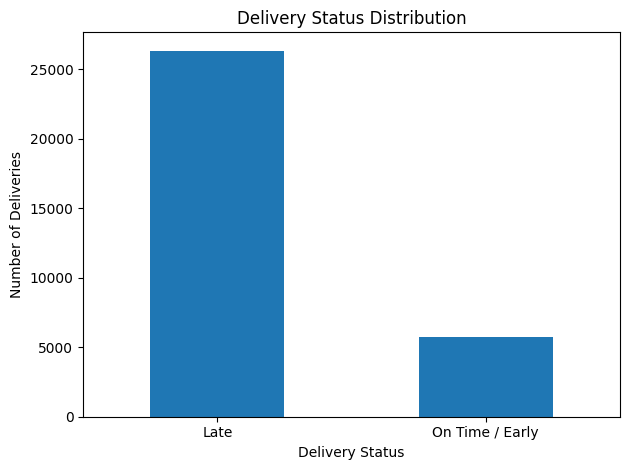

In [31]:
delivery_counts = df["delivery_status"].value_counts()

delivery_counts.plot(
    kind="bar",
    title="Delivery Status Distribution",
    xlabel="Delivery Status",
    ylabel="Number of Deliveries"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Analyse delivery deviation




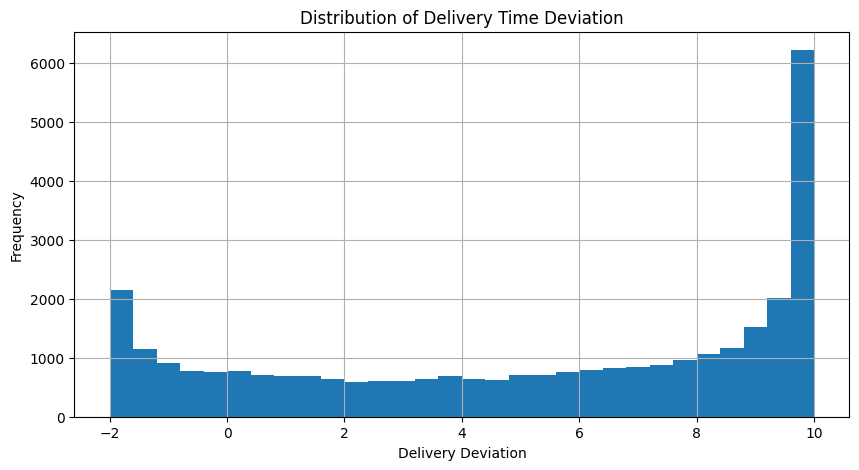

In [32]:
df["delivery_time_deviation"].hist(
    bins=30,
    figsize=(10, 5)
)

plt.title("Distribution of Delivery Time Deviation")
plt.xlabel("Delivery Deviation")
plt.ylabel("Frequency")
plt.show()

In [33]:
print(
    "Average Deviation:",
    round(df["delivery_time_deviation"].mean(), 2)
)

print(
    "Median Deviation:",
    round(df["delivery_time_deviation"].median(), 2)
)

Average Deviation: 5.18
Median Deviation: 6.11


Analyse risk classification

In [34]:
df["risk_classification"].value_counts()

,count
risk_classification,
High Risk,23944
Moderate Risk,5011
Low Risk,3110


In [35]:
risk_percentage = (
    df["risk_classification"]
    .value_counts(normalize=True) * 100
)

print(risk_percentage.round(2))

risk_classification
High Risk        74.67
Moderate Risk    15.63
Low Risk          9.70
Name: proportion, dtype: float64


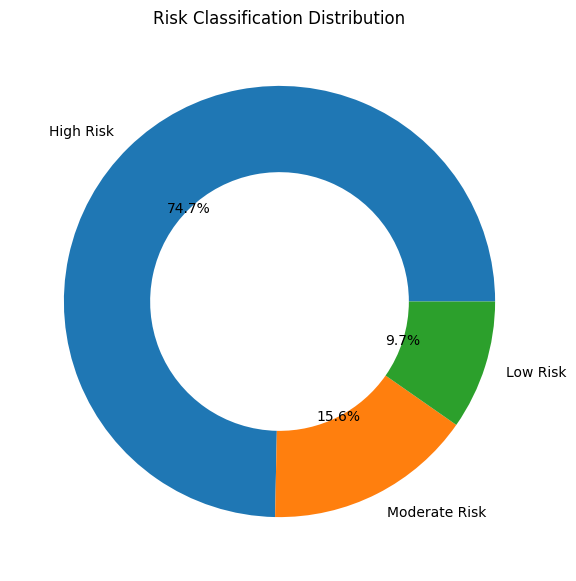

In [37]:
risk_percentage.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    wedgeprops={"width": 0.4}
)

plt.title("Risk Classification Distribution")
plt.ylabel("")
plt.show()

Analysis Monthly Trends

In [38]:
monthly_analysis = df.groupby("year_month").agg(
    total_deliveries=("is_late", "count"),
    late_rate=("is_late", "mean"),
    average_deviation=("delivery_time_deviation", "mean"),
    average_shipping_cost=("shipping_costs", "mean")
).reset_index()

monthly_analysis["late_rate"] *= 100

monthly_analysis.head()

,year_month,total_deliveries,late_rate,average_deviation,average_shipping_cost
0,2021-01,744,82.930108,5.107539,452.530112
1,2021-02,672,80.952381,5.156874,458.736899
2,2021-03,744,81.720430,5.324794,463.060885
3,2021-04,720,81.527778,5.025611,461.856876
4,2021-05,744,81.720430,4.982468,453.825271


chart

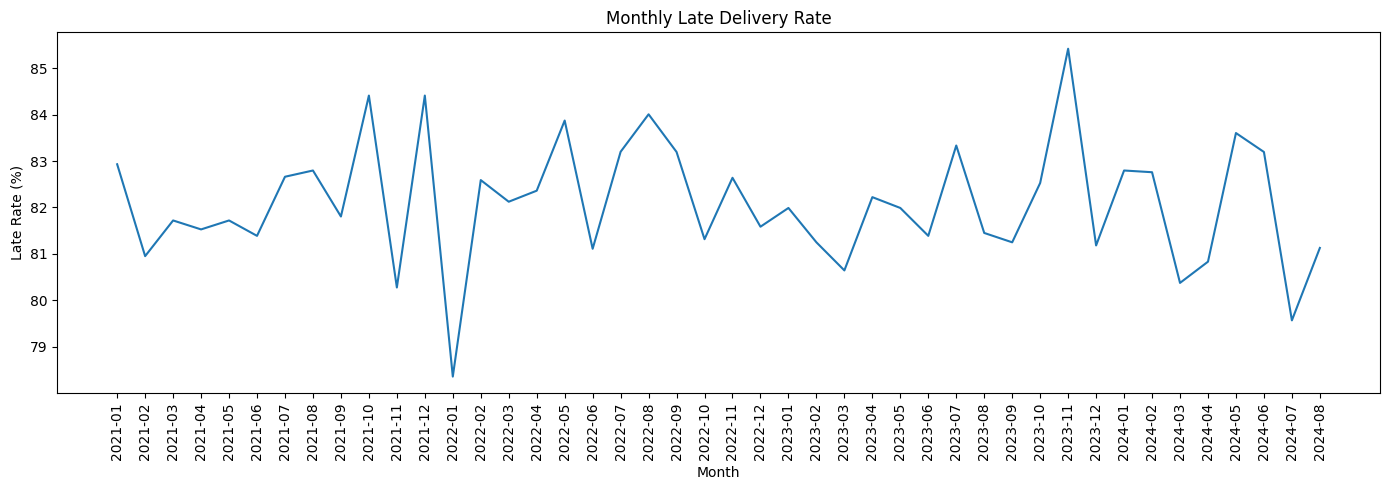

In [39]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_analysis["year_month"],
    monthly_analysis["late_rate"]
)

plt.title("Monthly Late Delivery Rate")

plt.xlabel("Month")

plt.ylabel("Late Rate (%)")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

Compare supplier reliability and delivery performance

In [40]:
supplier_analysis = df.groupby(
    "supplier_reliability_band",
    observed=True
).agg(
    total_records=("is_late", "count"),
    late_rate=("is_late", "mean"),
    average_deviation=("delivery_time_deviation", "mean"),
    average_cost=("shipping_costs", "mean")
).reset_index()

supplier_analysis["late_rate"] *= 100

print(supplier_analysis)

  supplier_reliability_band  total_records  late_rate  average_deviation  \
0                       Low          11771  81.964149           5.148008   
1                    Medium           8413  81.694996           5.190951   
2                      High          11881  82.501473           5.197594   

   average_cost  
0    458.556787  
1    460.000943  
2    459.740924  


CHART

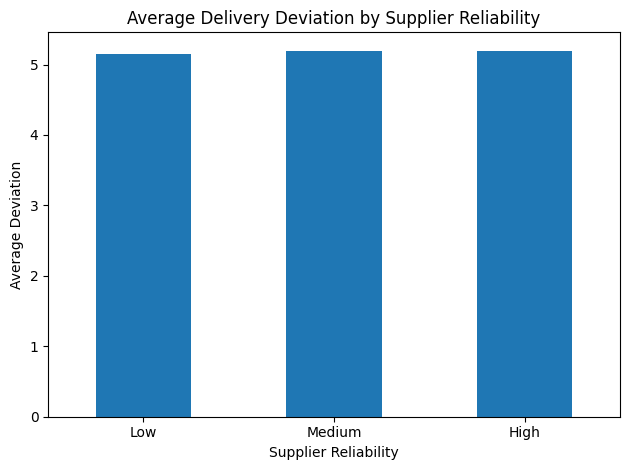

In [41]:
supplier_analysis.plot(
    x="supplier_reliability_band",
    y="average_deviation",
    kind="bar",
    legend=False,
    title="Average Delivery Deviation by Supplier Reliability"
)

plt.xlabel("Supplier Reliability")
plt.ylabel("Average Deviation")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Analyse lead time and shipping cost

In [42]:
leadtime_analysis = df.groupby(
    "lead_time_band",
    observed=True
).agg(
    total_records=("shipping_costs", "count"),
    average_cost=("shipping_costs", "mean"),
    average_deviation=("delivery_time_deviation", "mean")
).reset_index()

print(leadtime_analysis)

  lead_time_band  total_records  average_cost  average_deviation
0       1-3 Days          15365    460.647751           5.183625
1       3-7 Days           6692    460.961403           5.172899
2      7-15 Days          10008    456.358453           5.171648


CHART

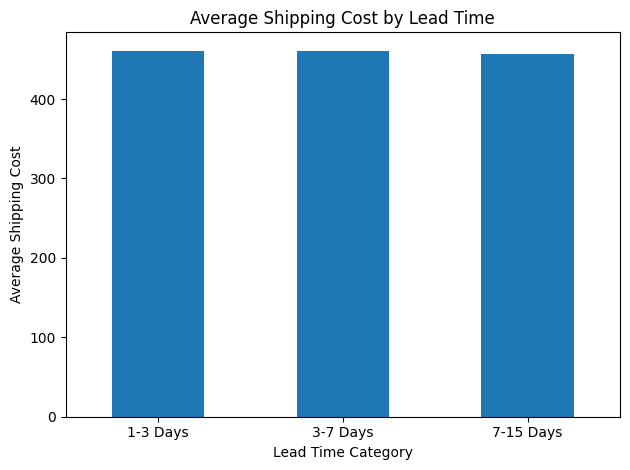

In [43]:
leadtime_analysis.plot(
    x="lead_time_band",
    y="average_cost",
    kind="bar",
    legend=False,
    title="Average Shipping Cost by Lead Time"
)

plt.xlabel("Lead Time Category")
plt.ylabel("Average Shipping Cost")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Analyse operational weak spots

In [45]:
low_inventory = (
    df["warehouse_inventory_level"] < 50
).mean() * 100

low_supplier = (
    df["supplier_reliability_score"] < 0.30
).mean() * 100

low_equipment = (
    df["handling_equipment_availability"] < 0.10
).mean() * 100

print("Low Inventory:", round(low_inventory, 2), "%")

print("Low Supplier Reliability:", round(low_supplier, 2), "%")

print("Low Equipment Availability:", round(low_equipment, 2), "%")

Low Inventory: 34.9 %
Low Supplier Reliability: 36.71 %
Low Equipment Availability: 43.22 %


Correlation analysis

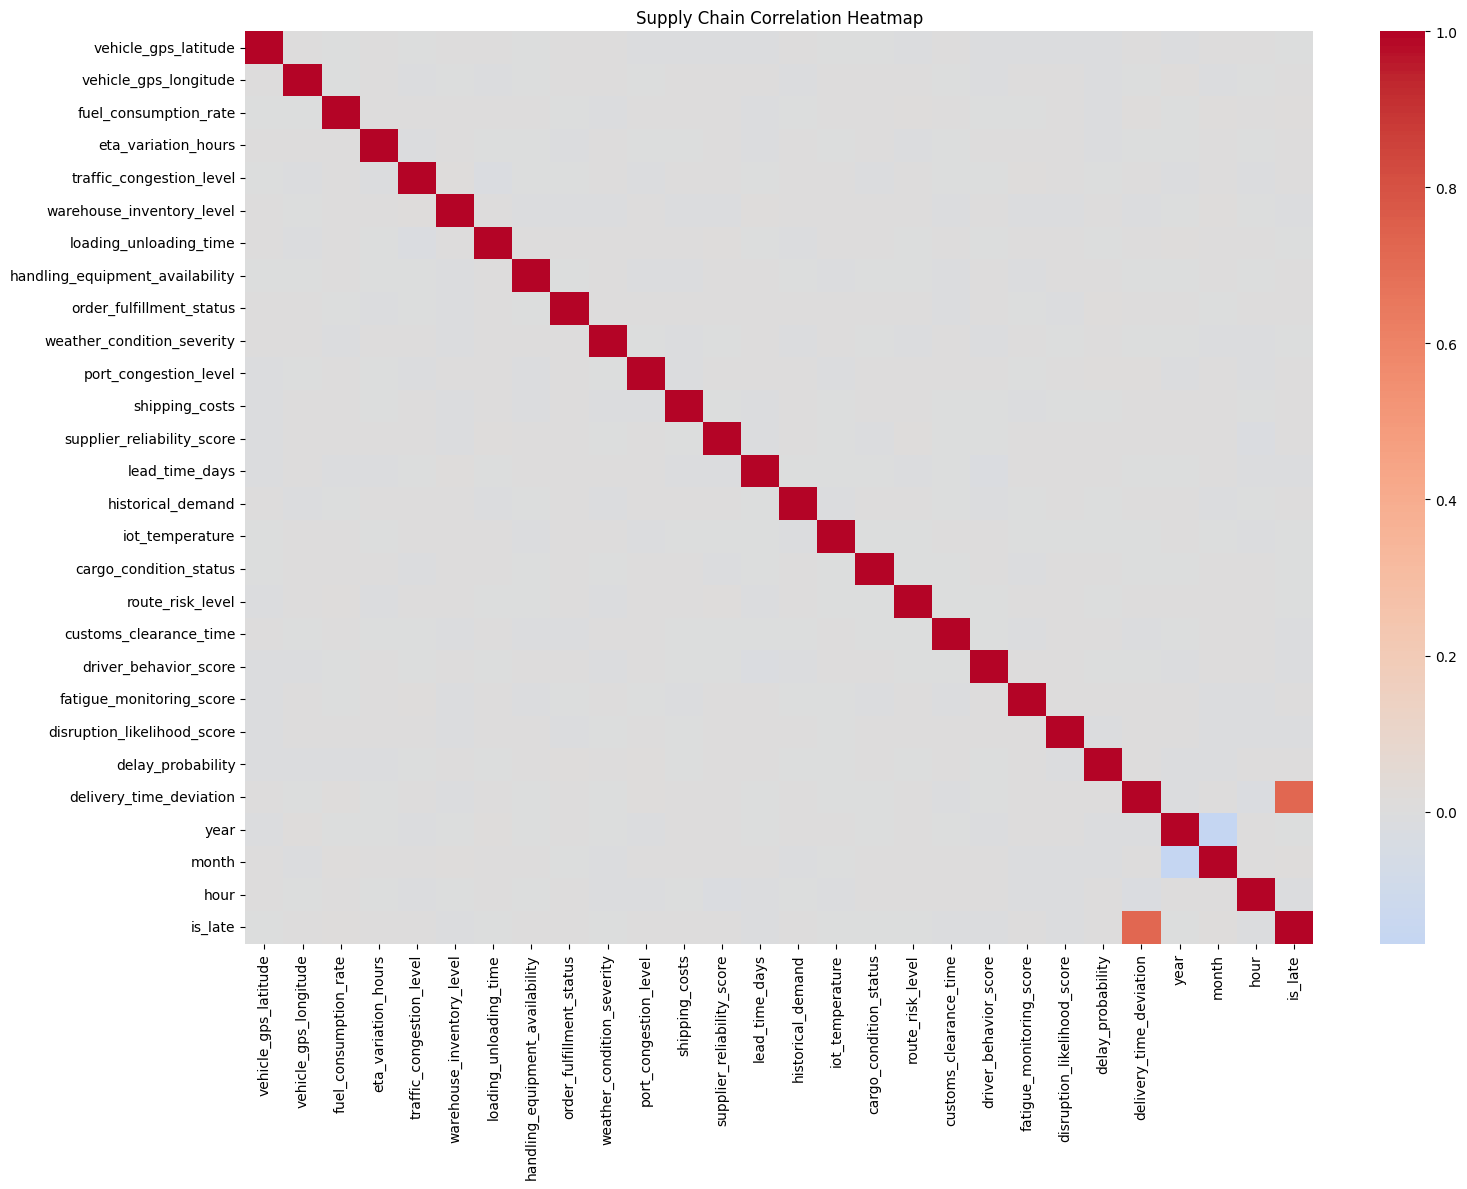

In [46]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Supply Chain Correlation Heatmap")

plt.tight_layout()

plt.show()

Validate your cleaned dataset

In [47]:
print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("Date Range:")
print(df["timestamp"].min(), "to", df["timestamp"].max())

Total Rows: 32065
Total Columns: 36
Missing Values: 0
Duplicate Rows: 0
Date Range:
2021-01-01 00:00:00 to 2024-08-29 00:00:00


In [48]:
df[[
    "year",
    "month",
    "hour",
    "is_late",
    "delivery_status",
    "supplier_reliability_band",
    "lead_time_band",
    "inventory_status"
]].head()

,year,month,hour,is_late,delivery_status,supplier_reliability_band,lead_time_band,inventory_status
0,2021,1,0,1,Late,High,1-3 Days,Normal Stock
1,2021,1,1,1,Late,Medium,7-15 Days,Normal Stock
2,2021,1,2,1,Late,Medium,7-15 Days,Normal Stock
3,2021,1,3,1,Late,High,3-7 Days,Low Stock
4,2021,1,4,1,Late,Medium,7-15 Days,Normal Stock


Export your cleaned CSV

In [50]:
df.to_csv(
    "chain.csv",
    index=False
)

print("Prepared CSV exported successfully!")

Prepared CSV exported successfully!


In [62]:
from google.colab import files

files.download("chain.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
df.shape

(32065, 36)

In [61]:
df["equipment_status"] = np.where(
    df["handling_equipment_availability"] < 0.10,
    "Low Availability",
    "Normal Availability"
)

In [63]:
from google.colab import files

files.download("chain.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
df.shape

(32065, 37)

In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32065 entries, 0 to 32064
Data columns (total 37 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   timestamp                        32065 non-null  datetime64[ns]
 1   vehicle_gps_latitude             32065 non-null  float64       
 2   vehicle_gps_longitude            32065 non-null  float64       
 3   fuel_consumption_rate            32065 non-null  float64       
 4   eta_variation_hours              32065 non-null  float64       
 5   traffic_congestion_level         32065 non-null  float64       
 6   warehouse_inventory_level        32065 non-null  float64       
 7   loading_unloading_time           32065 non-null  float64       
 8   handling_equipment_availability  32065 non-null  float64       
 9   order_fulfillment_status         32065 non-null  float64       
 10  weather_condition_severity       32065 non-null  float64  

In [67]:
from google.colab import files

files.download("chain.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>